In [1]:
import shap
from xgboost.sklearn import XGBClassifier
from sklearn.metrics import r2_score
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

In [2]:
def create_surrogate(X, predictions, sur_parameters):
    # Create surrogate xgboost model
    surrogate = XGBClassifier(**sur_parameters)
    surrogate.fit(X, predictions)
    sur_predictions = surrogate.predict(X)
    external_fidelity = r2_score(predictions, sur_predictions)

    return surrogate, external_fidelity

def calc_shap(model, x_explain, approximate=False):
    explainer = shap.TreeExplainer(model)
    shap_values = explainer.shap_values(x_explain, approximate=approximate)
    return shap_values, explainer

In [3]:
from sklearn.neural_network import MLPClassifier
# train original model and get its predictions
X, y = load_breast_cancer(return_X_y=True)
X_train, _, y_train, _ = train_test_split(X, y, random_state=42)
original_model = MLPClassifier()
original_model.fit(X_train, y_train)
predictions = original_model.predict(X)

# Use agnostic explainer
sur_parameters = {'n_estimators': 100, 'max_depth': 8}
surrogate_model, external_fidelity = create_surrogate(X,
                                                      predictions,
                                                      sur_parameters)
# get the shapley values for the whole dataset
shap_values, explainer = calc_shap(surrogate_model, X)

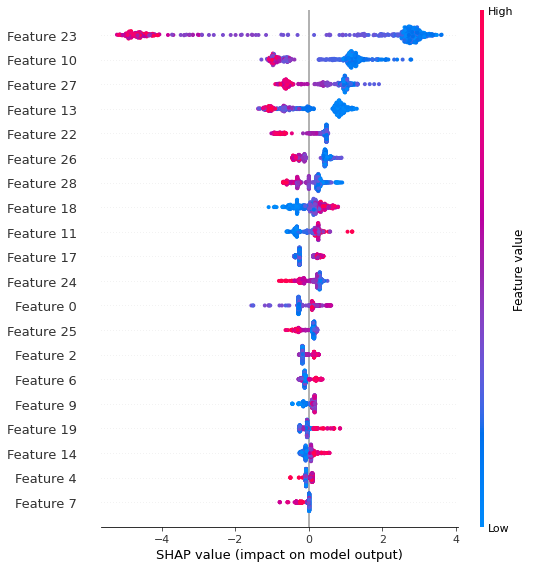

In [4]:
# summarize the effects of all the features
shap.summary_plot(shap_values, X)

## Manual predictions

In [5]:
from numpy import asarray

row = [11.51,23.93,74.52,2.5,0.0961,0.121,0.112,0.04105,0.188,0.657,0.288,2.904,1.936,16.97,0.0082,0.02982,0.05738,0.01267,0.01488,0.004738,12.48,37.16,113.28,474.2,0.1298,0.2517,0.363,0.09653,0.2112,0.08732]
input = asarray([row])
prediction = surrogate_model.predict(input)

In [6]:
if prediction.item(0) == 1:
    print("Breast cancer detected :(")
else:
    print("You are okey :)")

Breast cancer detected :(


## Explain the prediction

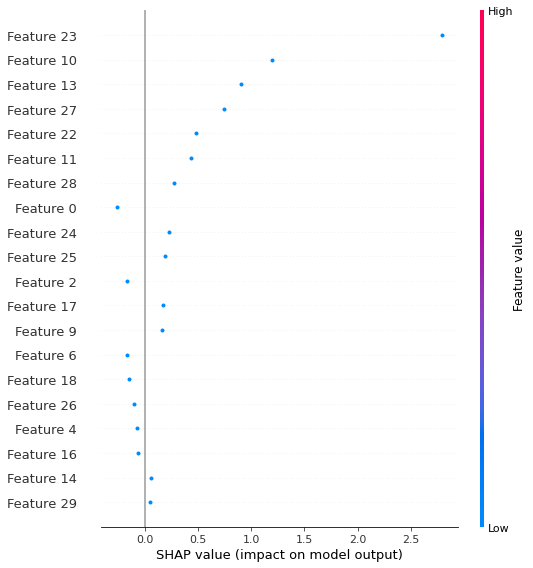

In [7]:
shap_values, explainer = calc_shap(surrogate_model, input)
shap.summary_plot(shap_values, input)

In [8]:
import pandas as pd
import numpy as np

vals= np.abs(shap_values).mean(0)

X_train = pd.DataFrame(X_train)

feature_importance = pd.DataFrame(list(zip(X_train.columns,vals)),columns=['col_name','feature_importance_vals'])
feature_importance.sort_values(by=['feature_importance_vals'],ascending=False,inplace=True)
feature_importance["col_name"] =  'Feature ' + feature_importance["col_name"].astype(str)

feature_importance.head()

,col_name,feature_importance_vals
23,Feature 23,2.787043
10,Feature 10,1.190984
13,Feature 13,0.908329
27,Feature 27,0.746489
22,Feature 22,0.480872
